In [1]:
2 + 2

4

In [2]:
3 * 4

12

In [3]:
120 / 4

30.0

In [4]:
nome = "Romeu"

In [5]:
print(nome)

Romeu


In [6]:
idade = 29
idade

29

In [7]:
formacao = "Marketing"
curso = "Data Science para Marketing"

In [8]:
print(f"Olá, {nome}! Notamos que você é formado em {formacao}. Bem vindo(a) ao curso {curso}")

Olá, Romeu! Notamos que você é formado em Marketing. Bem vindo(a) ao curso Data Science para Marketing


# Analisando o arquivo de campanha

In [9]:
import pandas as pd

In [10]:
campanha = pd.read_csv("/content/campanha.csv")

In [11]:
campanha.head()

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais
0,1,152431,9462,Email,13258,32309,MG,Brasil
1,1,39688,3218,PPC,16391,16568,BA,Brasil
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil
3,1,80768,3566,Google Ads,5215,0,PI,Brasil
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil


In [12]:
campanha['canal']

,canal
0,Email
1,PPC
2,Google Ads
3,Google Ads
4,Google Ads
...,...
49995,Social Media
49996,Google Ads
49997,Google Ads
49998,PPC


In [13]:
campanha['canal'].unique()

array(['Email', 'PPC', 'Google Ads', 'Meta Ads', 'Social Media'],
      dtype=object)

In [14]:
campanha['canal'].value_counts()

,count
canal,
Google Ads,25146
Meta Ads,15009
Social Media,4874
PPC,2526
Email,2445


CTR = (cliques/impressoes)*100

In [15]:
campanha['ctr'] = (campanha['cliques']/campanha['impressoes'])*100

In [16]:
campanha.head()

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,ctr
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399
1,1,39688,3218,PPC,16391,16568,BA,Brasil,8.108244
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477


<Axes: >

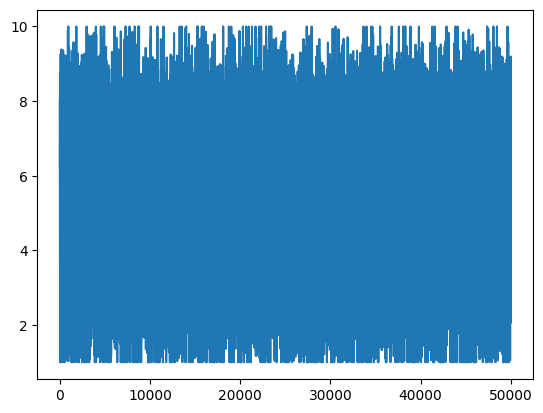

In [17]:
campanha['ctr'].plot()

<Axes: ylabel='Frequency'>

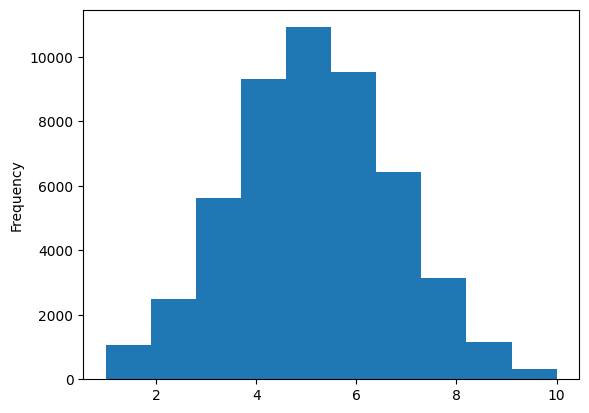

In [18]:
campanha['ctr'].plot(kind='hist')

In [19]:
campanha['ctr'].describe()

,ctr
count,50000.000000
mean,5.148482
std,1.604119
min,0.992663
25%,4.050781
50%,5.132384
75%,6.241502
max,10.000000


In [20]:
campanha['ctr'].median()

5.132384085295483

In [21]:
campanha['ctr'].mean()

np.float64(5.1484815905088634)

In [22]:
import seaborn as sns

<Axes: ylabel='ctr'>

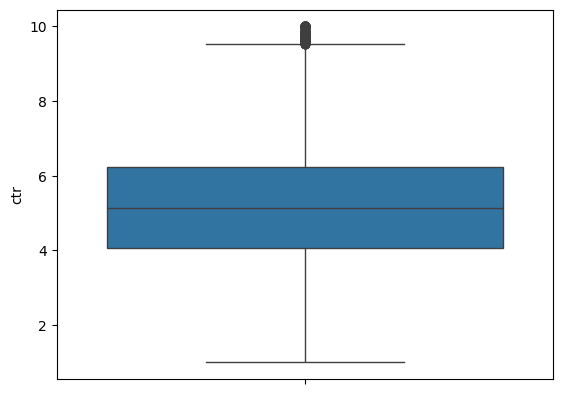

In [23]:
sns.boxplot(campanha['ctr'])

In [24]:
campanha.query('Id_campanha == 1 ')

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,ctr
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399
1,1,39688,3218,PPC,16391,16568,BA,Brasil,8.108244
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477
5,1,86472,3266,Google Ads,15870,12483,BA,Brasil,3.776945
6,1,63460,4869,Meta Ads,13769,10849,SP,Brasil,7.672550
7,1,45206,2231,Meta Ads,26270,8583,MA,Brasil,4.935186
8,1,85974,5340,Google Ads,42535,91,PE,Brasil,6.211180
9,1,128497,4717,Meta Ads,10310,19235,MS,Brasil,3.670903


In [25]:
campanha.query('Id_campanha == 1').mean(numeric_only=True)

,0
Id_campanha,1.000000
impressoes,96580.806452
cliques,4902.096774
custo,13863.419355
receita,14000.806452
ctr,5.210398


In [26]:
campanha.query('Id_campanha == 1')['impressoes']

,impressoes
0,152431
1,39688
2,104506
3,80768
4,54932
5,86472
6,63460
7,45206
8,85974
9,128497


In [27]:
campanha.query('Id_campanha == 1')['impressoes'].mean()

np.float64(96580.80645161291)

In [28]:
campanha.groupby('Id_campanha')['impressoes']

In [29]:
medias_por_campanha = campanha.groupby('Id_campanha')['impressoes'].mean()
medias_por_campanha.head()

,impressoes
Id_campanha,
1,96580.806452
2,92372.923077
3,118489.333333
4,96947.681818
5,105508.291667


<Axes: ylabel='Frequency'>

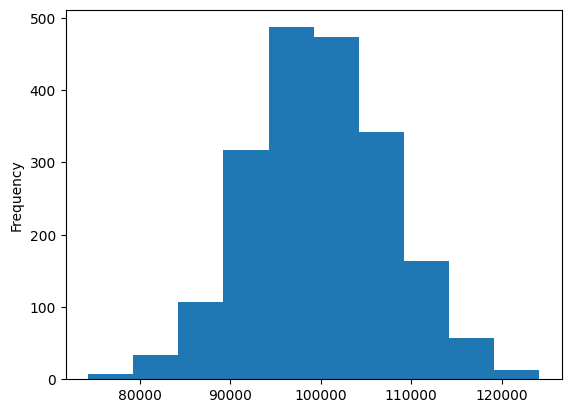

In [30]:
medias_por_campanha.plot(kind='hist')

In [31]:
metricas_por_tipo = campanha.groupby('canal')['ctr'].mean()
metricas_por_tipo

,ctr
canal,
Email,5.109386
Google Ads,5.152163
Meta Ads,5.133841
PPC,5.162208
Social Media,5.187068


<Axes: ylabel='impressoes'>

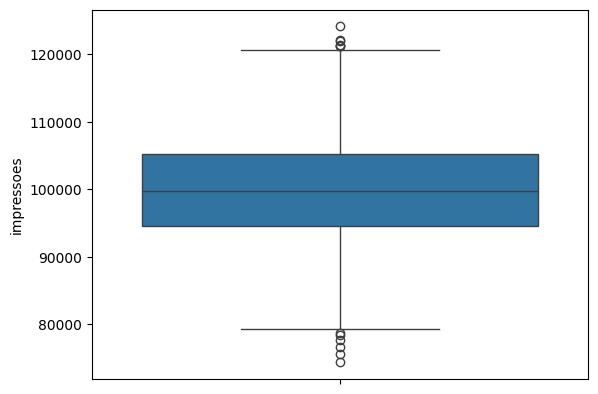

In [32]:
sns.boxplot(medias_por_campanha)

In [33]:
medias_por_campanha.describe()

,impressoes
count,2000.000000
mean,99924.847399
std,7651.690148
min,74315.388889
25%,94601.752717
50%,99731.860577
75%,105173.546176
max,124154.071429


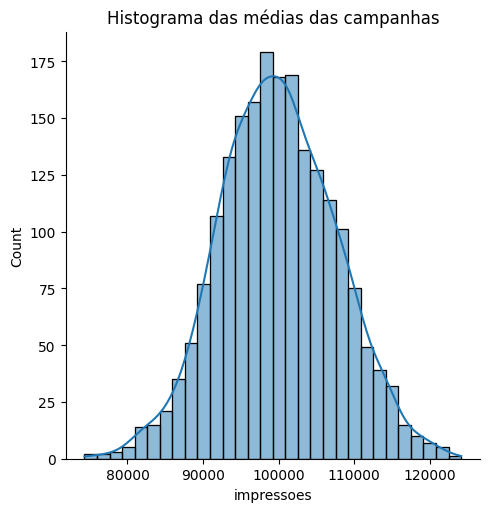

In [34]:
import matplotlib.pyplot as plt



sns.displot(medias_por_campanha, kde = True)

plt.title('Histograma das médias das campanhas')
plt.show()

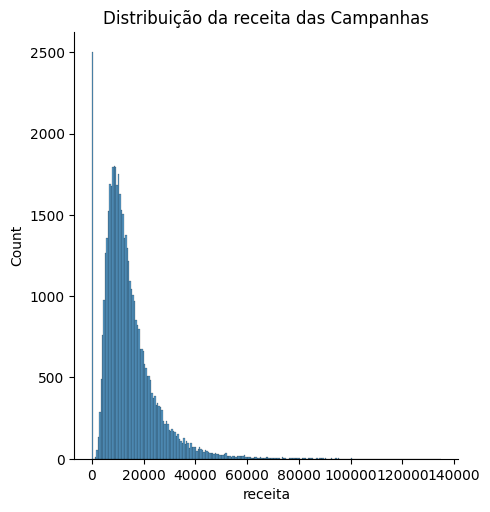

In [35]:
sns.displot(campanha['receita'])
plt.title('Distribuição da receita das Campanhas')
plt.show()

In [36]:
campanha.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Id_campanha  50000 non-null  int64  
 1   impressoes   50000 non-null  int64  
 2   cliques      50000 non-null  int64  
 3   canal        50000 non-null  object 
 4   custo        50000 non-null  int64  
 5   receita      50000 non-null  int64  
 6   estado       50000 non-null  object 
 7   pais         50000 non-null  object 
 8   ctr          50000 non-null  float64
dtypes: float64(1), int64(5), object(3)
memory usage: 3.4+ MB


In [37]:
campanha.describe()

,Id_campanha,impressoes,cliques,custo,receita,ctr
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000
mean,1004.637160,99916.792660,5146.89304,14478.263920,14242.518860,5.148482
std,578.014356,38217.517352,2612.96365,6072.944902,10365.240991,1.604119
min,1.000000,100.000000,1.00000,2723.000000,0.000000,0.992663
25%,504.000000,72238.000000,3209.00000,10164.000000,7757.000000,4.050781
50%,1007.000000,99951.500000,4829.00000,13348.000000,11855.500000,5.132384
75%,1506.000000,127436.000000,6741.25000,17513.000000,18070.250000,6.241502
max,2000.000000,200000.000000,19484.00000,80000.000000,134842.000000,10.000000


In [38]:
campanha['estado']

,estado
0,MG
1,BA
2,AL
3,PI
4,RJ
...,...
49995,MG
49996,MA
49997,RS
49998,DF


In [39]:
campanha['estado'].unique()

array(['MG', 'BA', 'AL', 'PI', 'RJ', 'SP', 'MA', 'PE', 'MS', 'DF', 'CE',
       'AM', 'SE', 'PA', 'PR', 'SC', 'GO', 'RN', 'RO', 'ES', 'MT', 'TO',
       'PB', 'RS', 'AC', 'AP', 'RR'], dtype=object)

In [40]:
campanha['estado'].value_counts()

,count
estado,
SP,11006
MG,4902
RJ,4221
BA,3524
RS,2701
PR,2698
PE,2255
CE,2140
PA,2024


In [41]:
campanha.head()


,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,ctr
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399
1,1,39688,3218,PPC,16391,16568,BA,Brasil,8.108244
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477


In [42]:
campanha['estado'].value_counts().index

Index(['SP', 'MG', 'RJ', 'BA', 'RS', 'PR', 'PE', 'CE', 'PA', 'SC', 'GO', 'MA',
       'AM', 'PB', 'ES', 'MT', 'RN', 'PI', 'AL', 'DF', 'MS', 'SE', 'RO', 'TO',
       'AC', 'AP', 'RR'],
      dtype='object', name='estado')

In [43]:
campanha['estado'].value_counts().values

array([11006,  4902,  4221,  3524,  2701,  2698,  2255,  2140,  2024,
        1741,  1715,  1643,   959,   952,   927,   839,   823,   784,
         784,   714,   674,   586,   445,   345,   226,   217,   155])

In [44]:
campanha['estado'].value_counts().to_frame()

,count
estado,
SP,11006
MG,4902
RJ,4221
BA,3524
RS,2701
PR,2698
PE,2255
CE,2140
PA,2024


In [45]:
contagem_de_estado = campanha['estado'].value_counts().to_frame().reset_index()

In [46]:
contagem_de_estado.columns = ['estado', 'total']

In [47]:
contagem_de_estado.head()

,estado,total
0,SP,11006
1,MG,4902
2,RJ,4221
3,BA,3524
4,RS,2701


<Axes: >

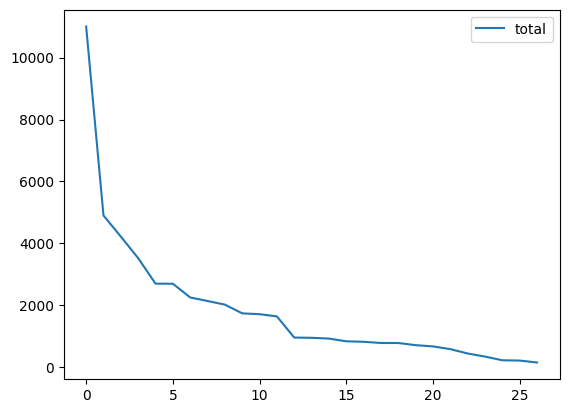

In [48]:
contagem_de_estado.plot()

<Axes: xlabel='estado', ylabel='total'>

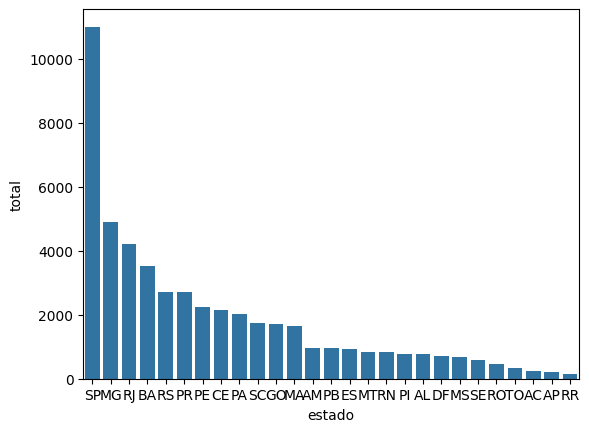

In [49]:
sns.barplot(data=contagem_de_estado, x ="estado", y = 'total')

<Axes: xlabel='estado', ylabel='count'>

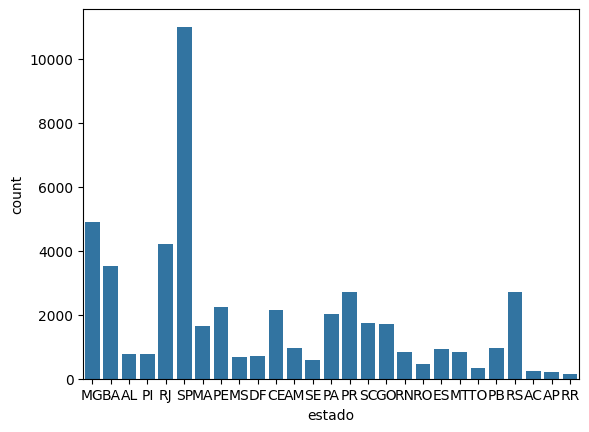

In [50]:
sns.countplot(data=campanha, x = 'estado')

<Axes: ylabel='total'>

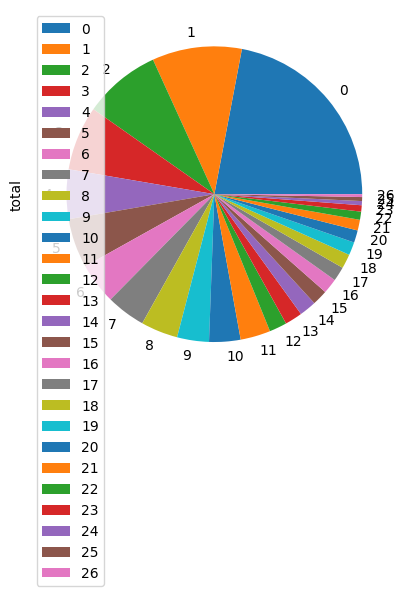

In [51]:
contagem_de_estado.plot(kind='pie', y='total')

<Axes: ylabel='total'>

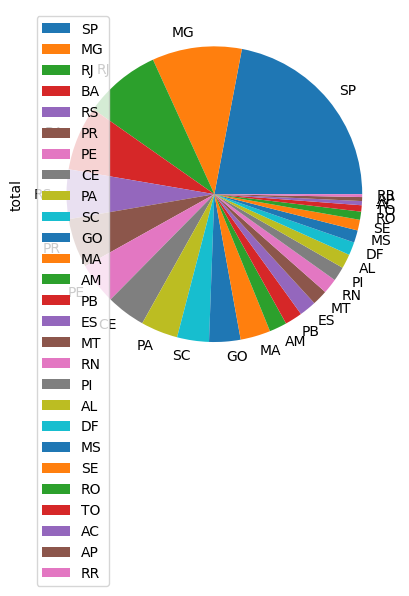

In [52]:
contagem_de_estado.plot(kind='pie', y='total', labels = contagem_de_estado['estado'])


In [53]:
total_por_estado = campanha['estado'].value_counts()
total_geral = total_por_estado.sum()
total_em_SP = total_por_estado['SP']
total_do_restante = total_geral - total_em_SP
print(total_geral,total_em_SP,total_do_restante)

50000 11006 38994


In [54]:
dados = {
    'estado' : ['SP', 'outros'],
      'total' : [total_em_SP, total_do_restante]
}

dados = pd.DataFrame(dados)
dados.head()

,estado,total
0,SP,11006
1,outros,38994


<Axes: ylabel='total'>

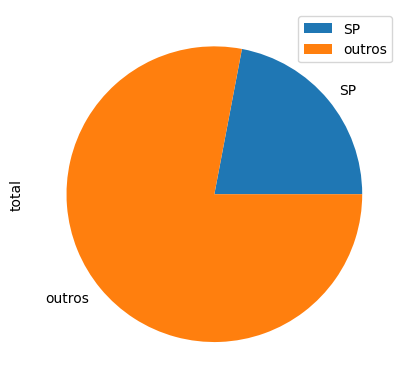

In [55]:
dados.plot(kind='pie', y = 'total', labels=dados['estado'])

In [56]:
total_de_outros_estados = campanha.query('estado != "SP" ')['estado'].value_counts()
total_de_outros_estados.head()

,count
estado,
MG,4902
RJ,4221
BA,3524
RS,2701
PR,2698


<Axes: xlabel='estado', ylabel='count'>

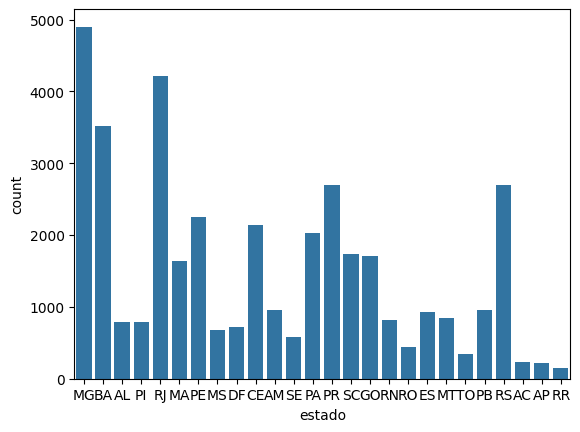

In [57]:
sns.countplot(data=campanha.query('estado != "SP"'), x='estado')

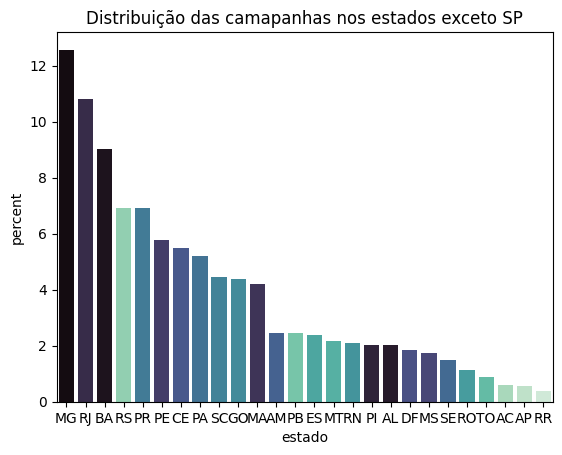

In [58]:
sns.countplot(data=campanha.query('estado != "SP"'),
              order=total_de_outros_estados.index,
              hue='estado',
              palette='mako',
              stat='percent',
              x='estado')

plt.title('Distribuição das camapanhas nos estados exceto SP')
plt.show()

In [59]:
campanha['roi'] = (campanha['receita'] - campanha['custo']) / campanha['custo']
campanha.head()


,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,ctr,roi
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399,1.436944
1,1,39688,3218,PPC,16391,16568,BA,Brasil,8.108244,0.010799
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935,2.074649
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115,-1.000000
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477,-0.473669


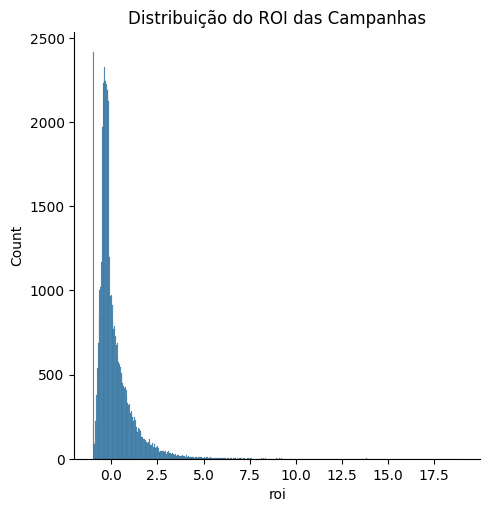

In [60]:
sns.displot(campanha['roi'])
plt.title('Distribuição do ROI das Campanhas')
plt.show()

In [61]:
metricas_google_ads = campanha.query('canal == "Google Ads"')
metricas_email = campanha.query('canal == "Email"')

media_metricas_google_ads = metricas_google_ads['roi'].mean()
media_metricas_email = metricas_email['roi'].mean()

print(media_metricas_google_ads, media_metricas_email)

0.13674573394615885 0.16903111529695838


In [62]:
[
    20000,
    20000,
    20000,
    20000,
    20000,
    20000,
    20000,
    20000,
    20000,
    20000,
    30000,
    30000,
    30000,
    30000,
    30000,
    30000,
    30000,
    30000,
    30000,
    30000,

]

[20000,
 20000,
 20000,
 20000,
 20000,
 20000,
 20000,
 20000,
 20000,
 20000,
 30000,
 30000,
 30000,
 30000,
 30000,
 30000,
 30000,
 30000,
 30000,
 30000]

In [63]:
import numpy as np

google_ads = [20000] * 10 + [30000] * 10
np.mean(google_ads)

np.float64(25000.0)

In [64]:
meta_ads = [40000] * 10 + [10000] * 10
np.mean(meta_ads)

np.float64(25000.0)

In [65]:
campanha0 = [25000] * 20
np.mean(campanha0)

np.float64(25000.0)

In [66]:
np.std(campanha0), np.std(google_ads), np.std(meta_ads)

(np.float64(0.0), np.float64(5000.0), np.float64(15000.0))

{'whiskers': [<matplotlib.lines.Line2D at 0x7f32f7de9310>,
 'caps': [<matplotlib.lines.Line2D at 0x7f32f7de9590>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f3301c9b750>,
 'medians': [<matplotlib.lines.Line2D at 0x7f32f7de9810>,
 'fliers': [<matplotlib.lines.Line2D at 0x7f32f7de9950>,
 'means': []}

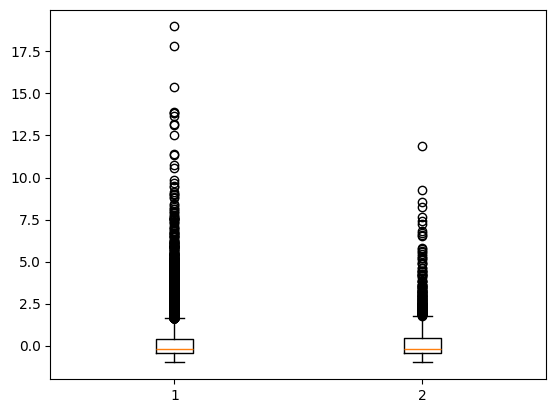

In [67]:
plt.boxplot([metricas_google_ads['roi'],metricas_email['roi']])

<Axes: xlabel='canal', ylabel='roi'>

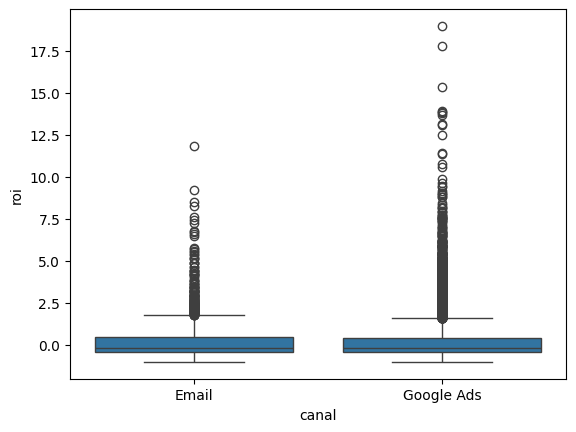

In [68]:
sns.boxplot(data=campanha.query('canal in ["Google Ads", "Email"]'),
          x = 'canal',
          y = 'roi')